In [4]:
from google.colab import drive
import os
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

# 1. First, check if the main Drive folder exists
base_path = '/content/drive/MyDrive/IML/EX4'

if os.path.exists(base_path):
    print(f"✅ Folder found: {base_path}")
    print("Files in this folder:")
    # List all files to see the correct spelling
    files = os.listdir(base_path)
    for f in files:
        print(f" - {f}")
else:
    print(f"❌ Folder not found: {base_path}")
    print("Try listing the contents of '/content/drive/MyDrive' to find the right folder name.")
    print(os.listdir('/content/drive/MyDrive'))

✅ Folder found: /content/drive/MyDrive/IML/EX4
Files in this folder:
 - Report ex4.gdoc
 - whichfaceisreal.zip


In [5]:
import zipfile

# 2. Define paths
# 'My Drive' is the standard root folder of your Google Drive
zip_path = '/content/drive/MyDrive/IML/EX4/whichfaceisreal.zip'
extract_path = '/content/dataset'  # We will extract it here to keep it organized

# 3. Unzip the file
print(f"Extracting {zip_path}...")

# Check if the file exists first to avoid errors
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Done! Files extracted to:", extract_path)
else:
    print(f"Error: File not found at {zip_path}. Please check the filename and path.")

Extracting /content/drive/MyDrive/IML/EX4/whichfaceisreal.zip...
Done! Files extracted to: /content/dataset


In [6]:
import os
import torch
import torch.nn as nn
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms
from tqdm import tqdm
import numpy as np

# Set seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [7]:
class ResNet18(nn.Module):
    def __init__(self, pretrained=False, probing=False):
        super(ResNet18, self).__init__()
        if pretrained:
            weights = ResNet18_Weights.IMAGENET1K_V1
            self.transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
            self.resnet18 = resnet18(weights=weights)
        else:
            self.transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
            self.resnet18 = resnet18()

        in_features_dim = self.resnet18.fc.in_features
        self.resnet18.fc = nn.Identity()

        if probing:
            for name, param in self.resnet18.named_parameters():
                param.requires_grad = False

        self.logistic_regression = nn.Linear(in_features_dim, 1)

    def forward(self, x):
        features = self.resnet18(x)
        # Pass features through the logistic regression layer
        out = self.logistic_regression(features)
        return out

In [8]:
def get_loaders(path, transform, batch_size):
    """
    Get the data loaders for the train, validation and test sets.
    """
    train_set = torchvision.datasets.ImageFolder(root=os.path.join(path, 'train'), transform=transform)
    val_set = torchvision.datasets.ImageFolder(root=os.path.join(path, 'val'), transform=transform)
    test_set = torchvision.datasets.ImageFolder(root=os.path.join(path, 'test'), transform=transform)

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size, shuffle=False)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader

def compute_accuracy(model, data_loader, device):
    """
    Compute the accuracy of the model on the data in data_loader
    """
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)
            # Apply threshold > 0 (since we use logits)
            predicted = (outputs > 0).float().squeeze()

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return correct / total

def run_training_epoch(model, criterion, optimizer, train_loader, device):
    """
    Run a single training epoch
    """
    model.train()
    total_loss = 0

    for (imgs, labels) in tqdm(train_loader, total=len(train_loader)):
        imgs = imgs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs = model(imgs)

        # Reshape labels to match output (Batch_Size, 1) and convert to float
        loss = criterion(outputs, labels.float().unsqueeze(1))

        # Backward and optimize
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)

In [24]:
# --- Configuration ---
# Select Model Type (Uncomment one)
# 1. From Scratch
# model = ResNet18(pretrained=False, probing=False)
# 2. Linear probing
# model = ResNet18(pretrained=True, probing=True)
# 3. Fine-tuning
model = ResNet18(pretrained=True, probing=False)

# Hyperparameters
batch_size = 32
num_of_epochs = 1  # Exercise asks for 1 epoch
learning_rate = 1e-5
path = '/content/dataset/whichfaceisreal' # UPDATE THIS PATH

# Setup
model = model.to(device)
transform = model.transform
train_loader, val_loader, test_loader = get_loaders(path, transform, batch_size)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# --- Training Loop ---
print(f"Starting training with LR={learning_rate}...")

for epoch in range(num_of_epochs):
    # Run a training epoch
    loss = run_training_epoch(model, criterion, optimizer, train_loader, device)

    # Compute accuracies
    train_acc = compute_accuracy(model, train_loader, device)
    val_acc = compute_accuracy(model, val_loader, device)

    print(f'Epoch {epoch + 1}/{num_of_epochs}, Loss: {loss:.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}')

# Final Test Accuracy
test_acc = compute_accuracy(model, test_loader, device)
print(f"Final Test Accuracy: {test_acc:.4f}")

Starting training with LR=1e-05...


100%|██████████| 44/44 [06:45<00:00,  9.22s/it]


Epoch 1/1, Loss: 0.6596, Train Acc: 0.7350, Val Acc: 0.6400
Final Test Accuracy: 0.6900


re-training BEST model to capture predictions...


100%|██████████| 44/44 [06:53<00:00,  9.39s/it]


re-training WORST model to capture predictions...


100%|██████████| 44/44 [06:47<00:00,  9.26s/it]


Searching for images...


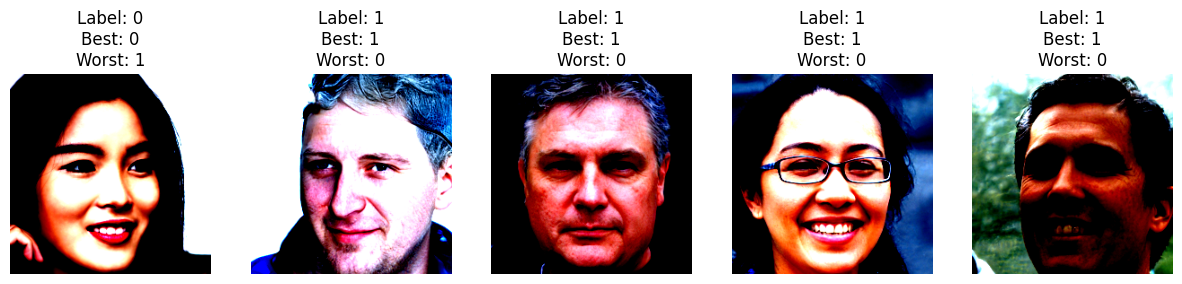

In [25]:
# import matplotlib.pyplot as plt
# --- 1. Define the Configurations based on your results ---
# Best: Fine-tuning, LR=0.0001
best_config = {'pretrained': True, 'probing': False, 'lr': 0.0001}

# Worst: Scratch, LR=0.01
worst_config = {'pretrained': False, 'probing': False, 'lr': 0.01}
def show_misclassified_images(best_model_config, worst_model_config, path, device):
    """
    Retrains the best and worst models to find interesting images.
    """
    print("re-training BEST model to capture predictions...")
    # Re-initialize and train Best Model
    best_model = ResNet18(pretrained=best_model_config['pretrained'], probing=best_model_config['probing']).to(device)
    optimizer = torch.optim.Adam(best_model.parameters(), lr=best_model_config['lr'])
    # Train for 1 epoch just to reproduce the state
    run_training_epoch(best_model, torch.nn.BCEWithLogitsLoss(), optimizer, train_loader, device)

    print("re-training WORST model to capture predictions...")
    # Re-initialize and train Worst Model
    worst_model = ResNet18(pretrained=worst_model_config['pretrained'], probing=worst_model_config['probing']).to(device)
    optimizer = torch.optim.Adam(worst_model.parameters(), lr=worst_model_config['lr'])
    run_training_epoch(worst_model, torch.nn.BCEWithLogitsLoss(), optimizer, train_loader, device)

    best_model.eval()
    worst_model.eval()

    found_images = []

    print("Searching for images...")
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            # Get predictions
            best_out = (best_model(imgs) > 0).float().squeeze()
            worst_out = (worst_model(imgs) > 0).float().squeeze()

            # Find indices where Best is Correct AND Worst is Wrong
            mask = (best_out == labels) & (worst_out != labels)
            indices = torch.where(mask)[0]

            for idx in indices:
                if len(found_images) < 5:
                    # Move image to cpu and undo normalization for plotting if needed
                    # (Here we just grab the tensor)
                    found_images.append((imgs[idx].cpu(), labels[idx].item(), best_out[idx].item(), worst_out[idx].item()))

            if len(found_images) >= 5:
                break

    # Plotting
    if len(found_images) == 0:
        print("Could not find 5 images meeting the criteria!")
        return

    fig, axes = plt.subplots(1, 5, figsize=(15, 5))
    for i, (img, label, best_pred, worst_pred) in enumerate(found_images):
        # Un-normalize or just transpose for display (C, H, W) -> (H, W, C)
        img_np = img.permute(1, 2, 0).numpy()
        # Clip to [0,1] range to avoid matplotlib warnings
        img_np = np.clip(img_np, 0, 1)

        axes[i].imshow(img_np)
        axes[i].set_title(f"Label: {label}\nBest: {int(best_pred)}\nWorst: {int(worst_pred)}")
        axes[i].axis('off')
    plt.show()

# --- HOW TO USE THIS ---
# 1. Update these dictionaries with the settings of YOUR actual best/worst results
# Example: If your best was Fine-Tuning with lr=0.0001
best_config = {'pretrained': True, 'probing': False, 'lr': 0.0001}

# Example: If your worst was Scratch with lr=0.1
worst_config = {'pretrained': False, 'probing': False, 'lr': 0.1}

# 2. Run the function
show_misclassified_images(best_config, worst_config, path, device)